# Buổi D6: Chia dữ liệu cho đúng với đời thật: theo nhóm và theo thời gian

**Hiện trường.** Chị Hạnh xây mô hình dự đoán tình trạng bệnh nhân từ các lần khám. Bảng có **nhiều lần khám cho mỗi bệnh nhân**. Cô chia ngẫu nhiên học/thi như thường lệ và được điểm rất đẹp. Khi triển khai ở bệnh viện khác, với **bệnh nhân mới**, điểm rơi mạnh.

Lý do: chia ngẫu nhiên để **cùng một bệnh nhân nằm ở cả học và thi**. Mô hình không học "bệnh" mà học **"nhận ra bệnh nhân"**. Tương tự, với dữ liệu theo **thời gian**, chia ngẫu nhiên để mô hình "nhìn thấy tương lai".

**Nguyên tắc của buổi:** cách chia thi phải **giống cách dùng thật**. Dùng cho bệnh nhân mới thì thi trên bệnh nhân mới. Dự báo tương lai thì thi trên tương lai.

**Lưu ý:** dữ liệu trong buổi này **tự dựng có chủ đích** bằng numpy để kiểm soát được sự thật; không phải dữ liệu bệnh nhân thật.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: điểm đẹp khi chia ngẫu nhiên, tệ khi gặp người mới |
| Chặng 1 | Chia theo nhóm: GroupKFold |
| Chặng 2 | Dữ liệu theo thời gian: chia ngẫu nhiên nhìn thấy tương lai |
| Chặng 3 | Chia theo thời gian: TimeSeriesSplit |
| Chặng 4 | Chọn cách chia cho đúng bài toán |

## Chặng 0: Thấy ngay, chia ngẫu nhiên và gặp người mới

**Câu hỏi:** cùng một mô hình, hai cách chia cho hai điểm khác hẳn?

Ta dựng bảng **200 bệnh nhân, mỗi người 10 lần khám** (2000 dòng). Mỗi bệnh nhân có **"nền riêng"** (một vector đặc trưng cố định: tuổi, cơ địa...) cộng chỉ số đo từng lần. Nhãn phần lớn do **nền riêng của bệnh nhân** quyết định, và chỉ có **một ít tín hiệu thật** từ chỉ số đo từng lần. Dựng như vậy để mô hình dễ "học thuộc người".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
rng = np.random.RandomState(0)
n_pat, n_visit = 200, 10
base = rng.randn(n_pat, 5)
patient_risk = base @ rng.randn(5) + rng.randn(n_pat) * 0.5
rows = []
for p in range(n_pat):
    for v in range(n_visit):
        meas = rng.randn(3)
        signal = 0.5 * meas[0]
        label = int(patient_risk[p] + signal + rng.randn() * 0.7 > 0)
        rows.append([p, *base[p], *meas, label])
cols = ["patient"] + [f"profile{i}" for i in range(5)] + [f"visit{i}" for i in range(3)] + ["sick"]
df = pd.DataFrame(rows, columns=cols)
X = df.drop(columns=["patient", "sick"]); y = df["sick"]; groups = df["patient"]
print(df.shape, "| sick share:", round(y.mean(), 3), "| visits per patient:", n_visit)

(2000, 10) | sick share: 0.48 | visits per patient: 10


**Giải thích từng dòng**

- `np.random.RandomState(0)`: máy tung xúc xắc có hạt giống cố định (đã dùng ở D1).
- `base @ rng.randn(5)`: toán tử `@` là **nhân ma trận**: tổ hợp 5 đặc trưng nền của mỗi người thành một điểm rủi ro riêng.
- `for p in range(n_pat): for v in range(n_visit):`: hai vòng lặp lồng nhau: với mỗi bệnh nhân, sinh 10 lần khám.
- `rows.append([p, *base[p], *meas, label])`: thêm một dòng: mã bệnh nhân, 5 đặc trưng nền (**giống nhau ở mọi lần khám của người đó**), 3 chỉ số đo lần này, nhãn. Dấu `*` trải danh sách ra từng phần tử.
- `pd.DataFrame(rows, columns=cols)`: gom thành bảng; `patient` là **mã nhóm**.

In [3]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
shuffled = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=0))
print("random KFold:", shuffled.round(3), "| mean", round(shuffled.mean(), 3))

random KFold: [0.74  0.775 0.772 0.738 0.762] | mean 0.758


**Giải thích từng dòng**

- `KNeighborsClassifier(n_neighbors=5)`: k láng giềng gần nhất (C3): đoán nhãn theo 5 dòng giống nhất. Nó rất giỏi tìm ra **lần khám khác của cùng một người** vì đặc trưng nền giống hệt.
- `KFold(5, shuffle=True, random_state=0)`: chia ngẫu nhiên theo **dòng**, bỏ qua việc dòng nào thuộc bệnh nhân nào.

**Cách đọc.**
- **Con số:** điểm khi chia ngẫu nhiên theo dòng: **75,8%**.
- **Bức tranh:** với 10 lần khám mỗi người, một lần khám trong tập thi hầu như luôn có "anh em" cùng bệnh nhân trong tập học. k-NN chỉ việc tìm anh em đó và chép nhãn. Điểm cao **không có nghĩa** là mô hình đoán được bệnh nhân **mới**.
- **Câu hỏi tiếp:** nếu thi bằng người chưa từng gặp thì sao?

**Mang về chặng 0:** khi một thực thể (bệnh nhân, khách hàng, máy móc) xuất hiện ở nhiều dòng, chia theo dòng để lọt thông tin của thực thể đó.

## Chặng 1: Chia theo nhóm, GroupKFold

**Câu hỏi:** làm sao để cả bệnh nhân nằm hẳn ở phần học hoặc hẳn ở phần thi?

Đời thường: lớp học có anh chị em ruột. Muốn thi công bằng thì **cả nhà** phải ở cùng một phòng (hoặc đi thi, hoặc đi học), không tách. `GroupKFold` làm vậy: mỗi **nhóm** (mã bệnh nhân) nằm trọn trong một phần.

In [4]:
from sklearn.model_selection import GroupKFold
gkf = GroupKFold(n_splits=5)
grouped = cross_val_score(model, X, y, cv=gkf, groups=groups)
tr, te = next(gkf.split(X, y, groups))
print("GroupKFold:", grouped.round(3), "| mean", round(grouped.mean(), 3))
print("patients in both train and test (first fold):", len(set(groups.iloc[tr]) & set(groups.iloc[te])))

GroupKFold: [0.732 0.672 0.735 0.735 0.74 ] | mean 0.723
patients in both train and test (first fold): 0


**Giải thích từng dòng**

- `GroupKFold(n_splits=5)`: bộ chia theo nhóm: không bao giờ tách một nhóm sang hai phía.
- `cross_val_score(..., groups=groups)`: phải đưa thêm `groups` (cột mã bệnh nhân) để bộ chia biết ai thuộc nhóm nào.
- `next(gkf.split(X, y, groups))`: lấy bộ chia đầu tiên (một cặp danh sách vị trí học, thi) để kiểm tra.
- `set(a) & set(b)`: giao của hai tập: những bệnh nhân có mặt ở **cả hai** phía. Kết quả mong đợi là 0.

**Cách đọc.**
- **Con số:** chia ngẫu nhiên **75,8%**, chia theo nhóm **72,3%**. Số bệnh nhân có mặt ở cả hai phía: **0**.
- **Bức tranh:** điểm cho **bệnh nhân mới** thấp hơn khoảng **3,4** điểm phần trăm. **Nói thật:** chênh lệch ở đây khiêm tốn vì nhãn nhiều nhiễu và k-NN với k = 5 chỉ nhờ vả anh em ở mức vừa phải; nó **lớn hơn** khi mỗi người có nhiều lần khám hơn, khi dùng k nhỏ, hoặc khi mô hình giỏi nhớ (xem thử thách 1 và 3). Dù lớn hay nhỏ, đó mới là con số để báo cáo nếu hệ thống dùng cho người chưa từng khám.
- **Mẹo kiểm tra:** luôn in giao của hai tập nhóm. Nếu khác 0, bộ chia đang sai.
- **Câu hỏi tiếp:** còn khi thực thể không phải người mà là *thời gian*?

**Mang về chặng 1:** nếu mô hình sẽ gặp thực thể mới khi dùng thật, chia theo thực thể (`GroupKFold`) và kiểm tra giao bằng 0.

## Chặng 2: Dữ liệu theo thời gian, chia ngẫu nhiên nhìn thấy tương lai

**Câu hỏi:** dự báo doanh số tháng sau, chia ngẫu nhiên có công bằng không?

Ta dựng **120 tháng** doanh số: **xu hướng tăng đều** cộng **mùa vụ** (cao vào cuối năm) cộng nhiễu. Mô hình: cây hồi quy dùng đặc trưng là chỉ số tháng và mùa.

Chia ngẫu nhiên nghĩa là mô hình đã học các tháng **trước và sau** tháng cần đoán, tức nội suy giữa hai hàng xóm. Dự báo thật chỉ được học **quá khứ**.

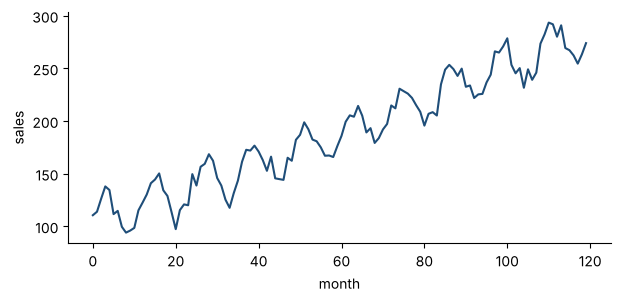

In [5]:
t = np.arange(120)
sales = 100 + 1.5 * t + 20 * np.sin(2 * np.pi * t / 12) + np.random.RandomState(0).randn(120) * 6
ts = pd.DataFrame({"t": t, "month_sin": np.sin(2 * np.pi * t / 12), "month_cos": np.cos(2 * np.pi * t / 12), "sales": sales})
Xt, yt = ts[["t", "month_sin", "month_cos"]], ts["sales"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(ts["t"], ts["sales"], color=BLUE); ax.set_xlabel("month"); ax.set_ylabel("sales")
plt.show()

**Giải thích từng dòng**

- `100 + 1.5 * t + 20 * np.sin(2 * np.pi * t / 12)`: doanh số = nền 100 + tăng 1,5 mỗi tháng + sóng mùa vụ chu kỳ 12 tháng.
- `month_sin, month_cos`: cách đưa **mùa** vào mô hình dưới dạng hai cột; tháng 12 và tháng 1 nằm cạnh nhau trên vòng tròn.

In [6]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
def cv_mae(model, cv):
    scores = cross_val_score(model, Xt, yt, cv=cv, scoring="neg_mean_absolute_error")
    return -scores.mean()
tree_r, lin_r = DecisionTreeRegressor(max_depth=8, random_state=0), LinearRegression()
rand_cv = KFold(5, shuffle=True, random_state=0)
print("random KFold  | tree MAE:", round(cv_mae(tree_r, rand_cv), 1), "| linear MAE:", round(cv_mae(lin_r, rand_cv), 1))

random KFold  | tree MAE: 8.3 | linear MAE: 5.2


**Giải thích từng dòng**

- `scoring='neg_mean_absolute_error'`: sklearn quy ước **điểm càng cao càng tốt**, nên sai số được đổi dấu thành số âm. Ta đổi dấu lại bằng `-scores.mean()`.
- `def cv_mae(model, cv):`: hàm trả về MAE trung bình (đơn vị: số tiền doanh số) của một mô hình dưới một cách chia.
- `DecisionTreeRegressor(max_depth=8)`: cây hồi quy: đoán bằng trung bình các tháng gần giống.
- `LinearRegression()`: đường thẳng: đã học ở B1.

**Cách đọc.** Khi chia ngẫu nhiên, cây cho MAE **8,3** và đường thẳng **5,2** (đơn vị: số tiền doanh số). Mỗi tháng thi có hàng xóm hai bên trong tập học, nên cây (vốn chép các hàng xóm gần) được hưởng lợi từ việc **nhìn thấy cả hai phía**.

**Câu hỏi tiếp:** nếu cả hai phải đoán **những tháng sau** tháng cuối cùng đã học thì sao?

**Mang về chặng 2:** chia ngẫu nhiên với chuỗi thời gian biến việc dự báo thành nội suy, dễ hơn thực tế rất nhiều.

## Chặng 3: Chia theo thời gian, TimeSeriesSplit

**Câu hỏi:** làm sao mô phỏng đúng việc "học quá khứ, đoán tương lai"?

`TimeSeriesSplit` chia thành nhiều vòng: vòng 1 học 20 tháng đầu, thi 20 tháng tiếp; vòng 2 học 40 tháng đầu, thi 20 tháng kế; ... **Phần thi luôn nằm sau phần học.**

In [7]:
from sklearn.model_selection import TimeSeriesSplit
tss = TimeSeriesSplit(n_splits=5)
for i, (tr, te) in enumerate(tss.split(Xt), start=1):
    print(f"round {i}: train months {tr.min()}-{tr.max()} | test months {te.min()}-{te.max()}")
print("time split | tree MAE:", round(cv_mae(tree_r, tss), 1), "| linear MAE:", round(cv_mae(lin_r, tss), 1))

round 1: train months 0-19 | test months 20-39
round 2: train months 0-39 | test months 40-59
round 3: train months 0-59 | test months 60-79
round 4: train months 0-79 | test months 80-99
round 5: train months 0-99 | test months 100-119


time split | tree MAE: 22.5 | linear MAE: 6.2


**Giải thích từng dòng**

- `TimeSeriesSplit(n_splits=5)`: bộ chia theo thời gian: phần học là một đoạn đầu ngày càng dài, phần thi là đoạn ngay sau đó.
- `tr.min()-tr.max()`: tháng đầu và tháng cuối của phần học; kiểm tra phần thi bắt đầu **sau** phần học.

**Cách đọc.**
- **Con số:** chia theo thời gian: cây MAE **22,5**, đường thẳng **6,2**. Chia ngẫu nhiên: cây **8,3**, đường thẳng **5,2**.
- **Bức tranh:** sai số của cây tăng từ **8,3** lên **22,5** (gấp khoảng 2,7 lần), còn đường thẳng chỉ từ **5,2** lên **6,2**. Lý do: cây hồi quy **không ngoại suy được**: nó chỉ trả về trung bình các tháng đã thấy, nên khi doanh số tiếp tục tăng vượt mức đã học, cây cứ đoán "bằng mức cũ". Đường thẳng nắm được xu hướng.
- **Hệ quả thực tế:** chia ngẫu nhiên báo cho bạn một sai số của cây **nhỏ hơn thực tế nhiều lần**. Nếu bạn lập kế hoạch kho dựa trên con số đó, sẽ thiếu hàng. Ở bài này đường thẳng thắng ở cả hai cách chia; nhưng độ lớn của sai số mới là điều chia sai làm méo.
- **Lưu ý:** `TimeSeriesSplit` còn có tham số `gap` (bỏ một khoảng giữa học và thi) và `test_size` (cỡ phần thi cố định) khi thông tin tháng trước tác động tháng sau.

**Mang về chặng 3:** với chuỗi thời gian, phần thi phải nằm sau phần học; đo bằng chia theo thời gian mới thấy mô hình nào dự báo được.

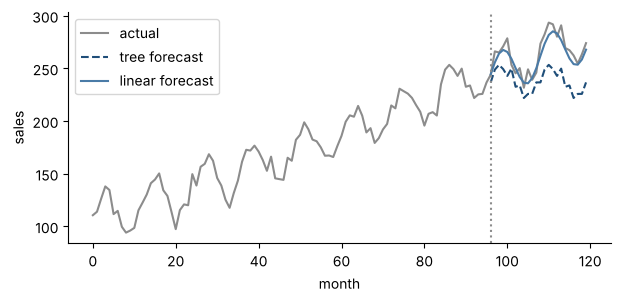

In [8]:
tr_idx = np.arange(0, 96); te_idx = np.arange(96, 120)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(ts["t"], ts["sales"], color=GRAY, label="actual")
ax.plot(te_idx, tree_r.fit(Xt.iloc[tr_idx], yt.iloc[tr_idx]).predict(Xt.iloc[te_idx]), color=BLUE, linestyle="--", label="tree forecast")
ax.plot(te_idx, lin_r.fit(Xt.iloc[tr_idx], yt.iloc[tr_idx]).predict(Xt.iloc[te_idx]), color="#4A7BA7", label="linear forecast")
ax.axvline(96, color=GRAY, linestyle=":"); ax.legend(); ax.set_xlabel("month"); ax.set_ylabel("sales")
plt.show()

**Giải thích từng dòng**

- `tr_idx = np.arange(0, 96)`: học 96 tháng đầu, đoán 24 tháng cuối.
- `tree_r.fit(...).predict(...)`: học trên quá khứ, đoán 24 tháng tương lai. Vạch chấm là thời điểm cắt.

**Cách đọc.** Đường đứt xanh (cây) đi **ngang** sau vạch cắt dù doanh số thật vẫn tăng; đường xanh nhạt (đường thẳng) tiếp tục lên cùng xu hướng. Đây là điều chia ngẫu nhiên không bao giờ cho bạn thấy.

## Chặng 4: Chọn cách chia cho đúng bài toán

**Câu hỏi:** khi nào dùng cách chia nào?

| Mô hình sẽ gặp gì khi dùng thật? | Cách chia | Công cụ |
|---|---|---|
| Dòng mới, độc lập (ảnh mới, thư mới) | Chia ngẫu nhiên, giữ tỉ lệ nhóm | `StratifiedKFold` |
| **Người, khách hàng, thiết bị mới** (một thực thể có nhiều dòng) | Chia theo nhóm | `GroupKFold` |
| **Tương lai** của cùng chuỗi | Chia theo thời gian | `TimeSeriesSplit` |
| Vừa thực thể mới, vừa nhóm hiếm | Chia theo nhóm có giữ tỉ lệ nhãn | `StratifiedGroupKFold` |

**Ba câu hỏi để chọn:**
1. Khi dùng thật, mô hình gặp **ai** (thực thể mới hay cũ)?
2. Khi dùng thật, mô hình gặp **khi nào** (sau thời điểm học)?
3. Có **dòng trùng** hoặc gần trùng không? (Kiểm tra bằng `df.duplicated().sum()`.)

Cách chia sai không báo lỗi; nó chỉ cho bạn một con số đẹp hơn thực tế.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Chia ngẫu nhiên theo dòng làm lọt thông tin của thực thể xuất hiện nhiều lần. |
| 1 | `GroupKFold` giữ cả nhóm ở một phía; kiểm tra giao bằng 0. |
| 2 | Chia ngẫu nhiên với chuỗi thời gian biến dự báo thành nội suy. |
| 3 | `TimeSeriesSplit`: thi luôn sau học; lộ ra mô hình không ngoại suy được. |
| 4 | Chọn cách chia theo cách mô hình sẽ được dùng thật. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Cả nhà ngồi cùng một phòng thi | chia theo nhóm | `GroupKFold`, `groups=` |
| Học quá khứ, thi tương lai | chia theo thời gian | `TimeSeriesSplit` |
| Nhìn thấy tháng sau khi đoán tháng này | rò rỉ thời gian | chia ngẫu nhiên trên chuỗi |
| Cây không đoán vượt mức đã thấy | không ngoại suy | `DecisionTreeRegressor` |
| Cách đưa "mùa" vào bảng | mã hóa chu kỳ | `sin`, `cos` |
| Khoảng trống giữa học và thi | khoảng đệm | `TimeSeriesSplit(gap=...)` |

**Thử thách tự làm**

1. Ở chặng 0, giảm số lần khám mỗi bệnh nhân từ 10 xuống 2 rồi 1. Khoảng cách giữa điểm chia ngẫu nhiên và điểm chia theo nhóm thay đổi ra sao? Vì sao?
2. Thêm tham số `gap=3` cho `TimeSeriesSplit` ở chặng 3. MAE của hai mô hình đổi thế nào?
3. Thử `n_neighbors=1` và `n_neighbors=25` ở chặng 0. Mô hình nào hưởng lợi nhiều nhất từ rò rỉ theo nhóm?
4. Nghĩ một ví dụ ở công việc của bạn mà dữ liệu có nhóm hoặc có thời gian. Bạn sẽ chia thế nào?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Nhận ra khi nào dữ liệu có thực thể xuất hiện nhiều dòng.
- [ ] Dùng `GroupKFold` và kiểm tra giao hai tập bằng 0.
- [ ] Giải thích vì sao chia ngẫu nhiên là sai với chuỗi thời gian.
- [ ] Dùng `TimeSeriesSplit` và đọc thứ tự học, thi.
- [ ] Chọn cách chia bằng ba câu hỏi.

## Phần thưởng (Tip pro): Bẫy dòng trùng và gần trùng


Một cách rò rỉ tầm thường nhưng phổ biến: **cùng một dòng xuất hiện hai lần** (do ghép bảng, nhập hai lần). Chia ngẫu nhiên có thể đặt bản sao vào tập thi và bản gốc vào tập học. Kiểm tra bằng `df.duplicated().sum()` **trước khi chia**. Với ảnh, văn bản hay bản ghi gần giống nhau (cùng một bài báo viết lại), hãy gom chúng thành một nhóm rồi dùng `GroupKFold`.